In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hyperillumination_utils import *
from astro_utils import *
from HItargets_utils import *
import os, contextlib, io
from dataclasses import replace
with contextlib.redirect_stdout(io.StringIO()):   # mute "no spidermanrc file detected"
    from simple_bias_analysis import overlay_planets

# Exoplanet Archive (to overlay known rocky planets on the a/Rs - Rp/Rs maps)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'NASAExoplanetArchive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Target planet: from the NASA Exoplanet Archive, or a CUSTOM entry in HItargets_utils (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI 2431 b") # "K2-141 b", "TOI-2431 b"

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from target data, will be set by theoretical stellar atmosphere models)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

In [3]:
# Basic Hyperillumination Stats
planet.summary(print_params=True, eff_wavelength_range=filter_lambda("MIRI/LRS"))

=== TOI-2431 b ===
    name = TOI-2431 b
  period = 0.22419578
    incl = 74.0
     ecc = 0.0
       w = 90.0
      r1 = 0.02131
      r2 = 1.0
       R = 2.080956345198848
  T2_eff = 4109.0
    a_AU = 0.0063
     T14 = 0.7475
--- derived ---
rp = r1/r2           = 0.0213
a  = R/r2            = 2.081
terminator_penumbra  = 60.6 deg
terminator_nightside = 118.1 deg
fraction_illuminated = 73.5 %  (fully illuminated: 25.5 %, penumbra: 48.1 %)
substellar_boost     = 2.07999 % (insolation), 0.51599 % (temperature)
approx_occ_depth     = 238.3 ppm


### Comparison Nguyen et al. (2020)

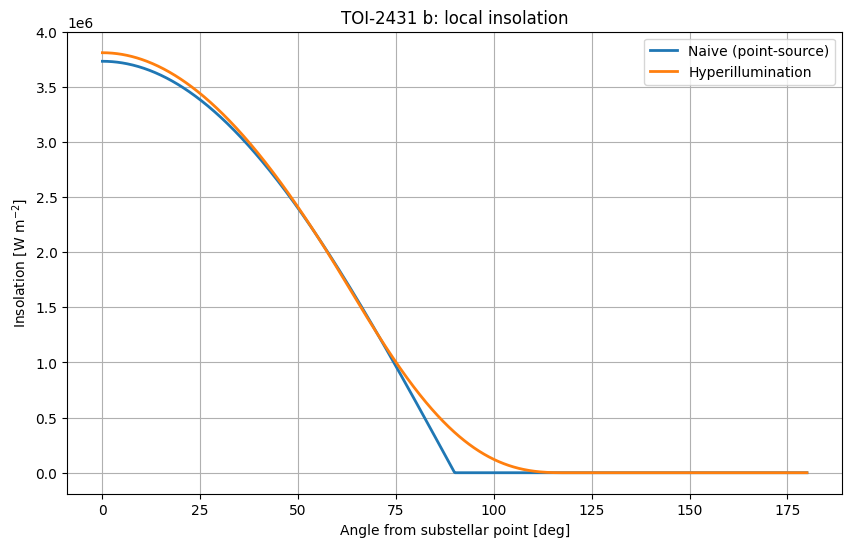

In [4]:
theta = np.linspace(0, 180, 1000)  # angle from substellar point [deg]
insol_naive = naive_insolation(np.radians(theta), planet)
insol_hyperillum = insolation_hyperillum(np.radians(theta), planet, u_B=u_B)

plt.figure(figsize=(10, 6))
plt.plot(theta, insol_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, insol_hyperillum, linewidth=2, label="Hyperillumination")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: local insolation")
plt.legend()
plt.grid()

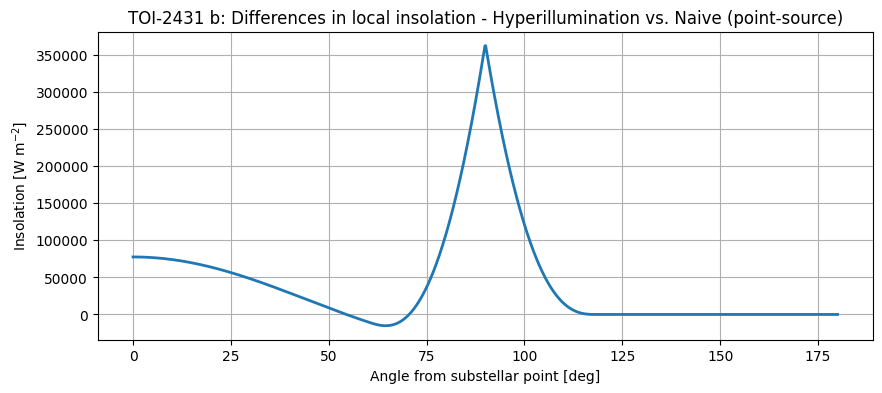

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(theta, insol_hyperillum-insol_naive, linewidth=2)
plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: Differences in local insolation - Hyperillumination vs. Naive (point-source)")
plt.grid()
plt.show()

Luger 2022 & Carter 2024 predict that hyper-illumination models predict a hotter substellar point than the plane-parallel approximation.

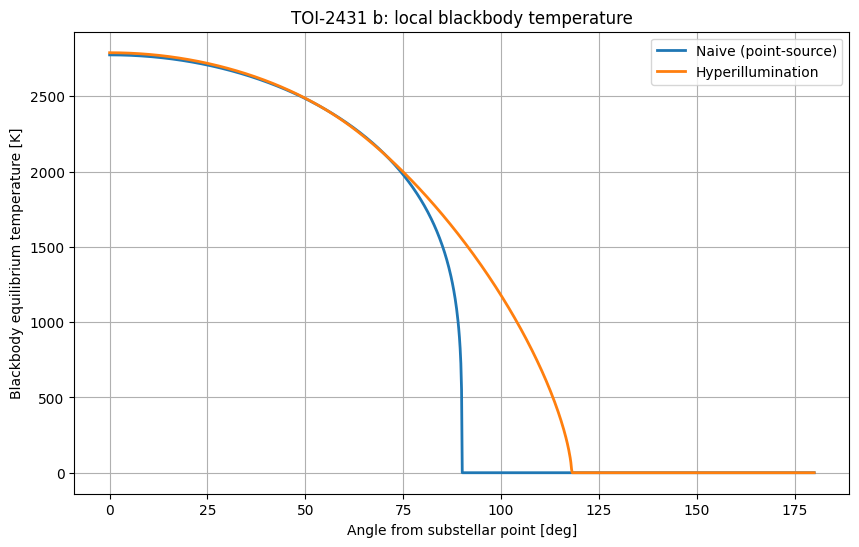

In [6]:
temp_naive = BBtemp_from_insolation(insol_naive)
temp_hyperillum = BBtemp_from_insolation(insol_hyperillum)

plt.figure(figsize=(10, 6))
plt.plot(theta, temp_naive, linewidth=2, label="Naive (point-source)")
plt.plot(theta, temp_hyperillum, linewidth=2, label="Hyperillumination")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Blackbody equilibrium temperature [K]")
plt.title(f"{planet.name}: local blackbody temperature")
plt.legend()
plt.grid()  

Temperature at 90° is about 1550 K, so the local blackbody spectrum peaks at about 1.9 µm (TOI-2431 b, $A_B = 0.1$, $u_B = 0.6$). 
MIRI: 4.9 to 28.8 microns.

insolation_penumbra_mask runtime: 1.1939 s
insolation_penumbra_hyperillum runtime: 0.0031 s
insolation_penumbra_hyperillum_simpleint runtime: 2.5133 s
insolation_penumbra_hyperillum_approx runtime: 0.0000 s


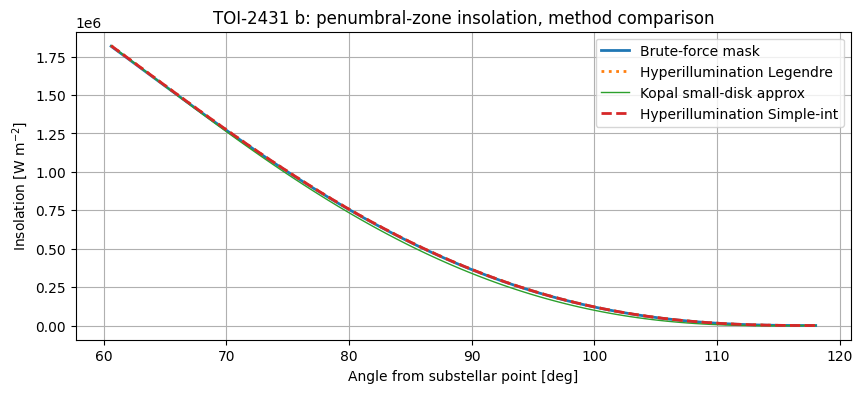

In [7]:
theta_pen = np.linspace(planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg"), 100)

insol_mask = insolation_penumbra_mask(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_legendre = insolation_penumbra_hyperillum(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_simpleint = insolation_penumbra_hyperillum_simpleint(np.radians(theta_pen), planet, runtime=True, u_B=u_B)
insol_hyperillum_approx = insolation_penumbra_hyperillum_approx(np.radians(theta_pen), planet, runtime=True, u_B=u_B)

plt.figure(figsize=(10, 4))
plt.plot(theta_pen, insol_mask, linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, insol_hyperillum_legendre, linewidth=2, linestyle=":", label="Hyperillumination Legendre")
plt.plot(theta_pen, insol_hyperillum_approx, linewidth=1, label="Kopal small-disk approx")
plt.plot(theta_pen, insol_hyperillum_simpleint, linewidth=2, linestyle="--", label="Hyperillumination Simple-int")


plt.xlabel("Angle from substellar point [deg]")
plt.ylabel(r"Insolation [W m$^{-2}$]")
plt.title(f"{planet.name}: penumbral-zone insolation, method comparison")
plt.legend()
plt.grid()

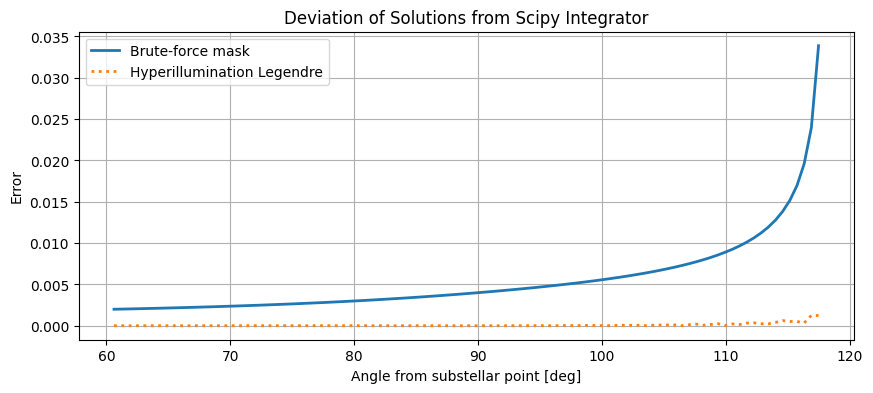

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(theta_pen, np.abs(1-insol_mask/insol_hyperillum_simpleint), linewidth=2, label="Brute-force mask")
plt.plot(theta_pen, np.abs(1-insol_hyperillum_legendre/insol_hyperillum_simpleint), linewidth=2, linestyle=":", label="Hyperillumination Legendre")
#plt.plot(theta_pen, np.abs(1-insol_hyperillum_approx/insol_hyperillum_simpleint), linewidth=1, label="Kopal small-disk approx")

plt.xlabel("Angle from substellar point [deg]")
plt.ylabel("Error")
plt.title("Deviation of Solutions from Scipy Integrator")
plt.legend()
plt.grid()

### Illuminated Fractions of Exoplanet

In [9]:
planet.fraction_illuminated("extra")

{'fully illuminated': np.float64(0.25460561622151484),
 'penumbra': np.float64(0.48054828363275626)}

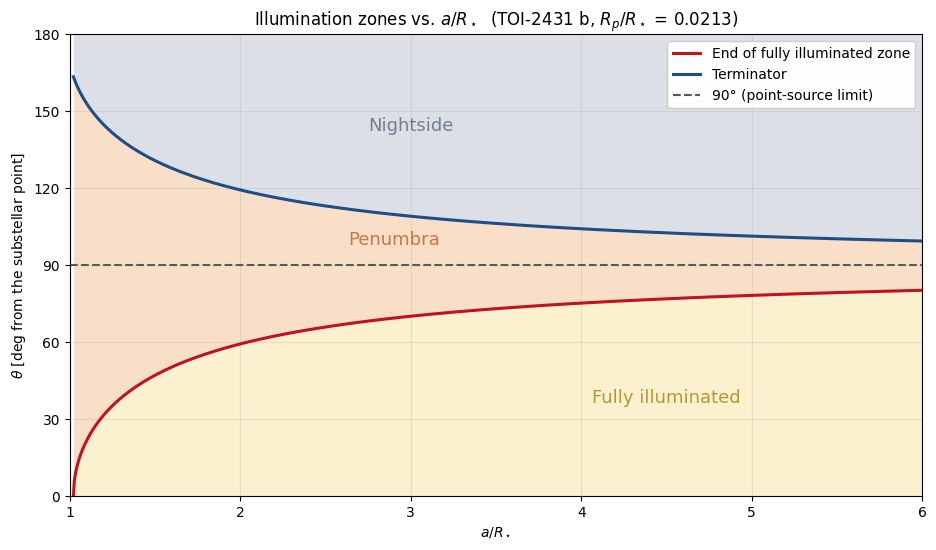

In [10]:
# Illumination zones along a/Rs at the planet's own Rp/Rs, from PlanetParams' definitions (array-valued R, r2 = 1): the end of the fully illuminated zone,
# theta_in = arccos((1 + Rp/Rs) / (a/Rs)), and the terminator, theta_out = arccos(-(1 - Rp/Rs) / (a/Rs)); both tend to the plane-parallel 90 deg as a/Rs grows. The planet's own a/Rs is marked.
rp_rs, a_rs_planet = planet.r1 / planet.r2, planet.R / planet.r2
ars = np.linspace(1. + rp_rs, 6., 1000)
sweep = replace(planet, r1=rp_rs, r2=1., R=ars)
theta_in, theta_out = sweep.terminator_penumbra(unit="deg"), sweep.terminator_nightside(unit="deg")
theta_in_p, theta_out_p = planet.terminator_penumbra(unit="deg"), planet.terminator_nightside(unit="deg")

fig, ax = plt.subplots(figsize=(11, 6))
c_fi, c_pen, c_night, c_planet = "#f4d35e", "#ee964b", "#8d99ae", "#2a9d8f"
ax.fill_between(ars, 0., theta_in, color=c_fi, alpha=0.3, lw=0, zorder=0)
ax.fill_between(ars, theta_in, theta_out, color=c_pen, alpha=0.3, lw=0, zorder=0)
ax.fill_between(ars, theta_out, 180., color=c_night, alpha=0.3, lw=0, zorder=0)
ax.plot(ars, theta_in, color="#c1121f", lw=2.2, label="End of fully illuminated zone")
ax.plot(ars, theta_out, color="#1d4e89", lw=2.2, label="Terminator")
ax.axhline(90., ls="--", color="0.35", lw=1.5, label="90° (point-source limit)")

# the planet: its a/Rs, and its two angles read off the curves
# ax.axvline(a_rs_planet, color=c_planet, ls=":", lw=2.2, zorder=3, label=planet.name)
# ax.plot([a_rs_planet] * 2, [theta_in_p, theta_out_p], "o", color=c_planet, ms=8, mec="white", mew=1.2, zorder=6)
# for th, dy in ((theta_in_p, -1), (theta_out_p, 1)):
#     ax.annotate(f"{th:.1f}°", (a_rs_planet, th), xytext=(10, 9 * dy), textcoords="offset points", ha="left", va="center", fontsize=10, color=c_planet, zorder=6)

# zone labels: plain, muted text in the tone of each band (nightside left of the legend; penumbra above the 90° line, where the band is wide)
label_kw = dict(ha="center", va="center", fontsize=13, alpha=0.75, zorder=5)
ax.text(4.5, np.interp(4.5, ars, theta_in) / 2., "Fully illuminated", color="#9c7a00", **label_kw)
ax.text(2.9, (90. + np.interp(2.9, ars, theta_out)) / 2., "Penumbra", color="#b4541a", **label_kw)
ax.text(3., (np.interp(3., ars, theta_out) + 180.) / 2., "Nightside", color="#4f5d75", **label_kw)

ax.set(xlim=(1., 6.), ylim=(0., 180.), xlabel=r"$a/R_\star$", ylabel=r"$\theta$ [deg from the substellar point]",
       title=rf"Illumination zones vs. $a/R_\star$  ({planet.name}, $R_p/R_\star$ = {rp_rs:.4f})")
ax.set_yticks(np.arange(0, 181, 30)); ax.set_xticks(np.arange(1, 7))
ax.legend(loc="upper right", fontsize=10, framealpha=0.95)
ax.grid(alpha=0.3)
plt.show()

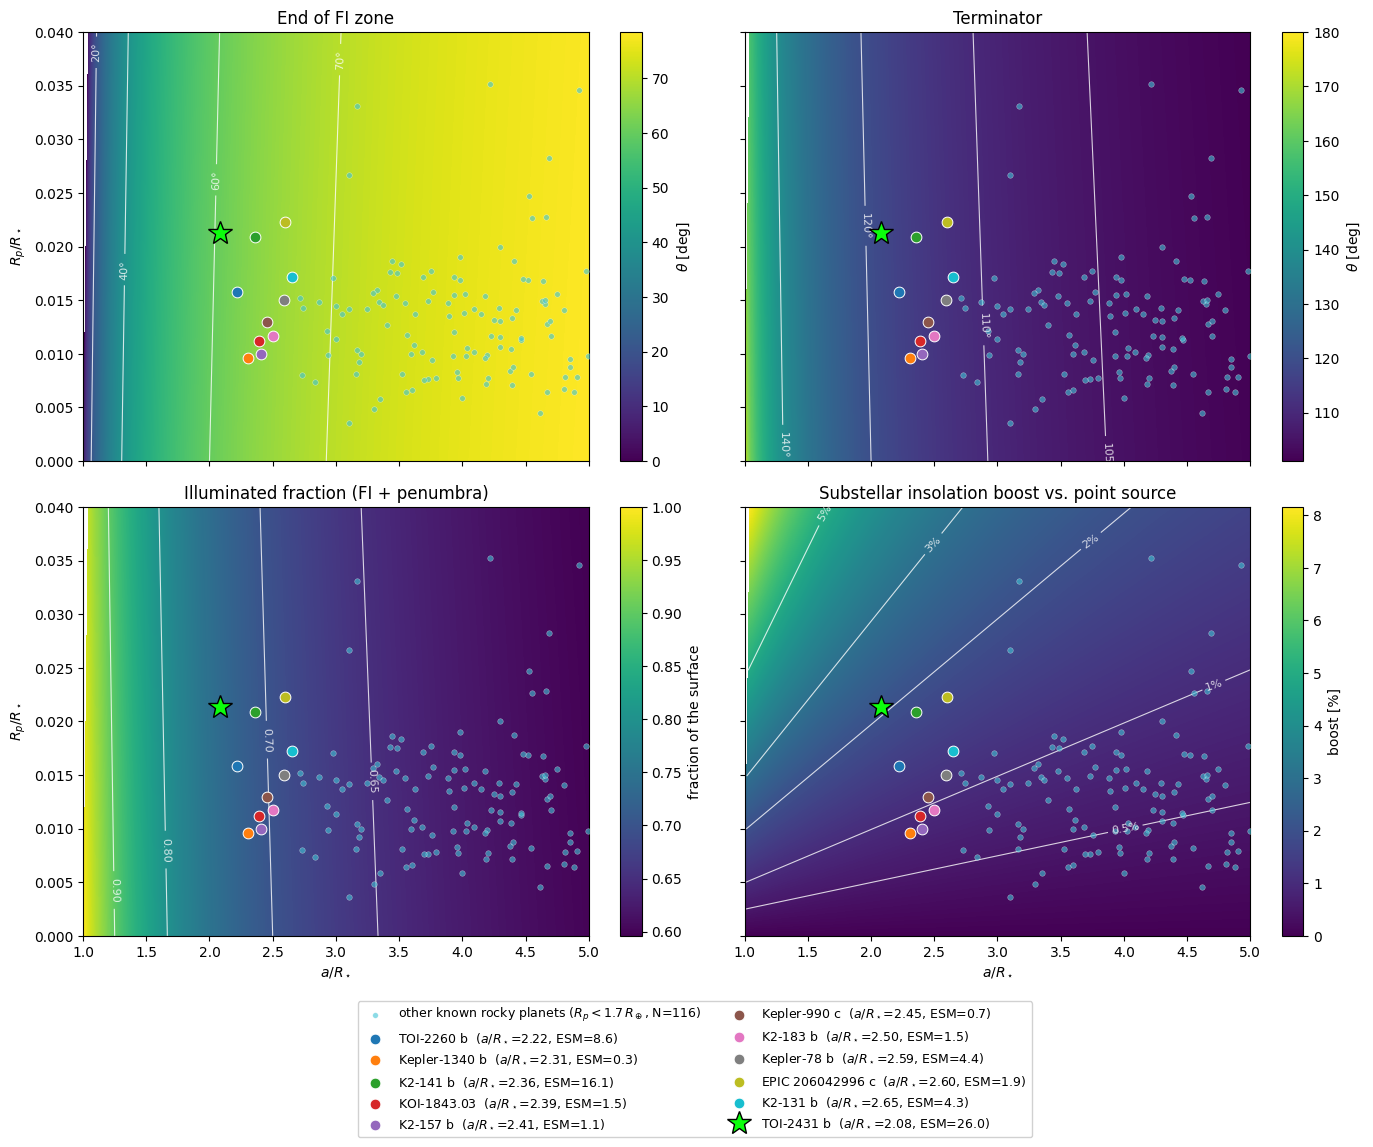

In [11]:
rprs_grid = np.linspace(0., 0.04, 1000)   # r1/r2
ars_grid = np.linspace(1., 5., 1000)    # R/r2
RPRS, ARS = np.meshgrid(rprs_grid, ars_grid, indexing="ij")
valid = ARS >= 1. + RPRS                  # otherwise the planet overlaps the star

# The whole grid as ONE PlanetParams with array-valued r1, R (r2 = 1): the class methods are elementwise, so the maps use exactly the same definitions as for a single planet
grid_planet = replace(planet, r1=RPRS, r2=1., R=ARS)
with np.errstate(invalid="ignore", divide="ignore"):
    maps = [
        (grid_planet.terminator_penumbra(unit="deg"),   "End of FI zone",                             r"$\theta$ [deg]",   [20, 40, 60, 70],     "%d°"),
        (grid_planet.terminator_nightside(unit="deg"),  "Terminator",                                 r"$\theta$ [deg]",   [105, 110, 120, 140], "%d°"),
        (grid_planet.fraction_illuminated(),            "Illuminated fraction (FI + penumbra)",       "fraction of the surface", [0.65, 0.7, 0.8, 0.9], "%.2f"),
        (100. * grid_planet.substellar_boost(),         "Substellar insolation boost vs. point source", "boost [%]",     [0.5, 1, 2, 3, 5],    "%g%%"),
    ]

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (z, title, clabel, levels, fmt) in zip(axs.flat, maps):
    z = np.where(valid, z, np.nan)
    im = ax.pcolormesh(ars_grid, rprs_grid, z, shading="auto", cmap="viridis")
    cs = ax.contour(ars_grid, rprs_grid, z, levels=levels, colors="w", linewidths=.8, alpha=.8)
    ax.clabel(cs, fmt=fmt, fontsize=8, inline_spacing=3)
    fig.colorbar(im, ax=ax, label=clabel)
    overlay_planets(AGG, ax, "pl_ratror", (rprs_grid[0], rprs_grid[-1]), a_rs_lim=(ars_grid[0], ars_grid[-1]), target=planet)
    ax.set_title(title)
    ax.set_xlim(ars_grid[0], ars_grid[-1]); ax.set_ylim(rprs_grid[0], rprs_grid[-1])
for ax in axs[1]: ax.set_xlabel(r"$a/R_\star$")
for ax in axs[:, 0]: ax.set_ylabel(r"$R_p/R_\star$")

# one shared legend: the 10 rocky planets with the smallest a/Rs are named, the rest are background dots
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9, framealpha=.9)
plt.tight_layout()
plt.show()

### Convergence to Naive model
With growing a/Rs the star shrinks towards a point source, so the hyper-illuminated insolation profile should converge to the naive (plane-parallel) cosine profile. The naive curve is normalized to its own maximum; each hyperillumination curve is divided by the naive maximum at the same a/Rs, so its peak directly shows the substellar boost (1 + `substellar_boost`) and the penumbra extends past 90°. The normalized naive curve is the same for every a/Rs, so a single one suffices.

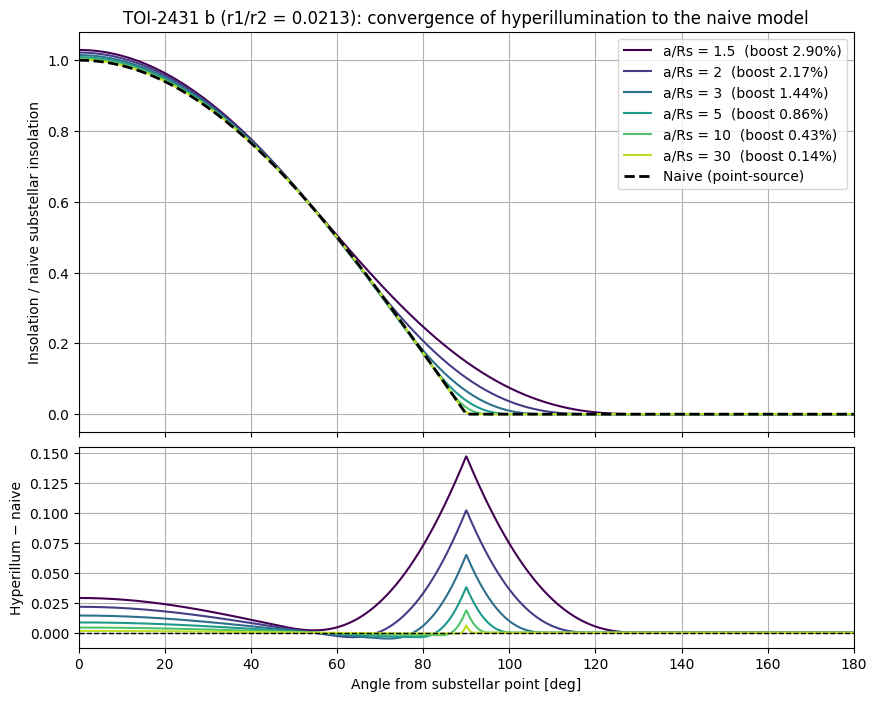

In [12]:
ars_values = [1.5, 2, 3, 5, 10, 30]                 # R/r2 (planet's own value: planet.R/planet.r2)
theta = np.linspace(0, 180, 2000)                   # angle from substellar point [deg]
gamma1 = np.radians(theta)

# Normalized naive profile (identical for all a/Rs: cos(gamma1) clipped at 90 deg)
insol_naive_norm = naive_insolation(gamma1, planet) / naive_insolation(gamma1, planet).max()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1], hspace=0.05))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(ars_values)))

for ars, color in zip(ars_values, colors):
    p = replace(planet, R=ars * planet.r2)          # keep r1, r2 of "planet", only change the orbital distance
    insol_hyper_norm = insolation_hyperillum(gamma1, p, u_B=u_B) / naive_insolation(gamma1, p).max()
    ax_top.plot(theta, insol_hyper_norm, color=color, linewidth=1.5, label=f"a/Rs = {ars:g}  (boost {100*p.substellar_boost():.2f}%)")
    ax_bot.plot(theta, insol_hyper_norm - insol_naive_norm, color=color, linewidth=1.5)

ax_top.plot(theta, insol_naive_norm, color="black", linestyle="--", linewidth=2, label="Naive (point-source)")
ax_bot.axhline(0, color="black", linestyle="--", linewidth=1)

ax_top.set_ylabel("Insolation / naive substellar insolation")
ax_top.set_title(f"{planet.name} (r1/r2 = {planet.r1/planet.r2:.4f}): convergence of hyperillumination to the naive model")
ax_top.legend()
ax_top.grid()

ax_bot.set_xlabel("Angle from substellar point [deg]")
ax_bot.set_ylabel("Hyperillum − naive")
ax_bot.set_xlim(0, 180)
ax_bot.grid()
plt.show()

### Planetary Insolation-/Heatmaps

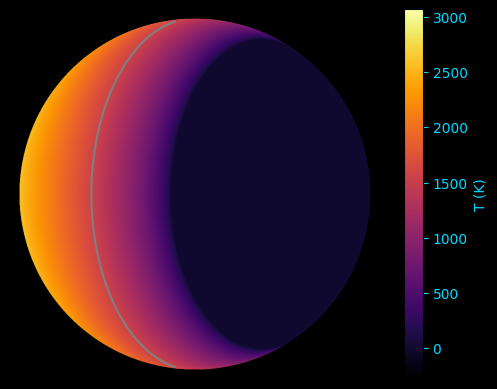

In [13]:
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="hyperillum", terminator=True, unit="temperature", u_B=u_B)

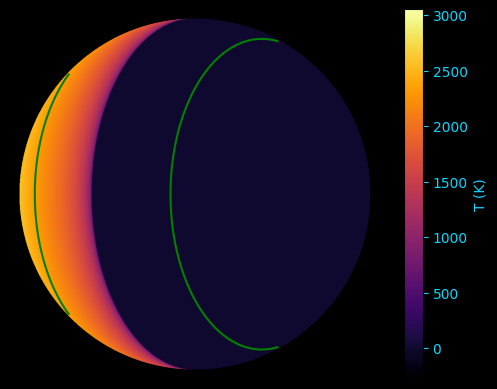

In [14]:
phase = 0.35
ax=plot_insolmap(phase, planet, insolation_model="naive", show_penumbra="both", unit="temperature", u_B=u_B)

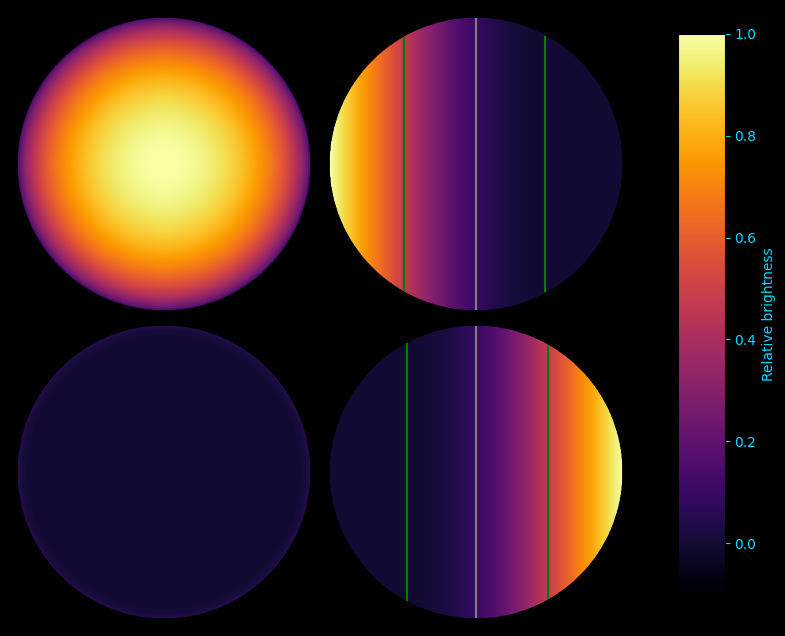

In [15]:
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, show_penumbra="both", unit="flux", u_B=u_B)

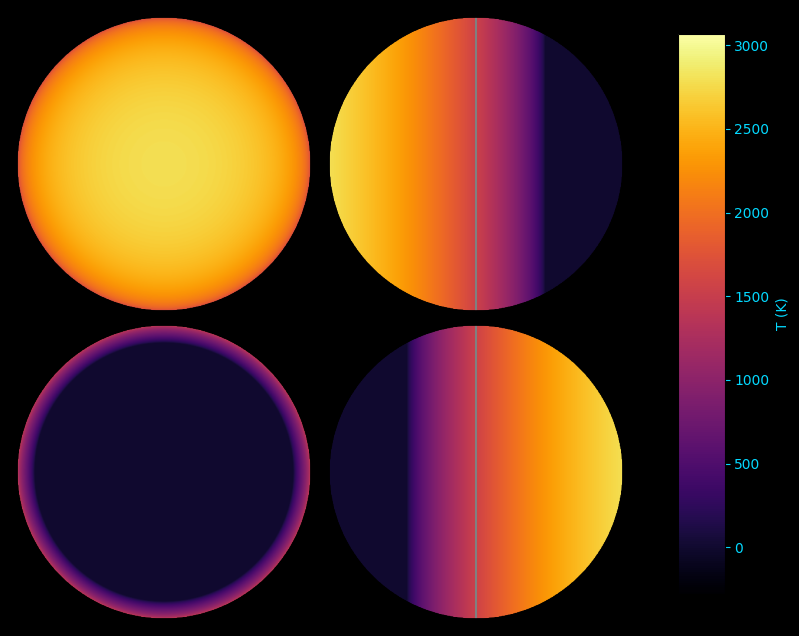

In [16]:
ax=plot_quad_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="temperature", u_B=u_B) # , show_penumbra="both"

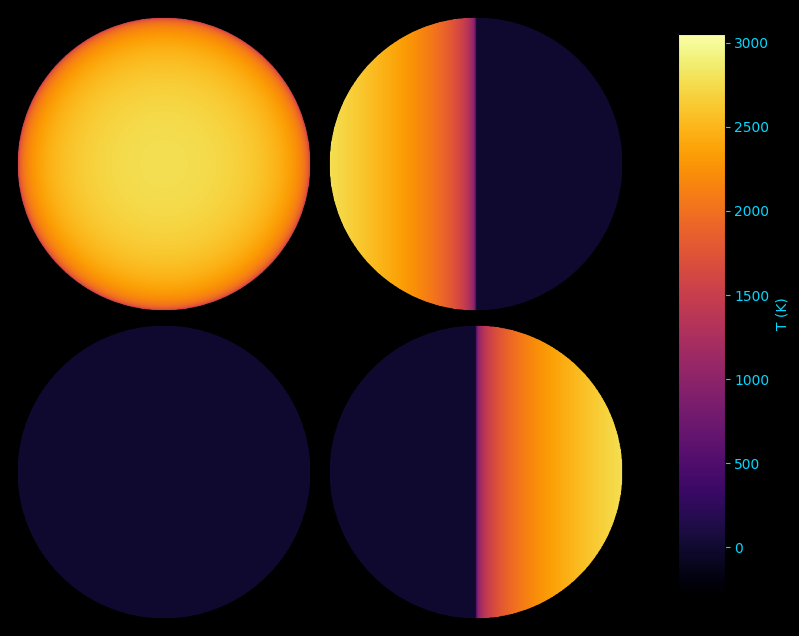

In [17]:
ax=plot_quad_insolmap(planet, insolation_model="naive", unit="temperature", u_B=u_B)

### Point source vs extended source at quadrature and on the nightside (shared colour bar)

The talk figure for slide 5: one 2 x 2 of temperature maps, rows = insolation model (point source / extended source), columns = viewing phase (quadrature / nightside), all four panels on one temperature scale so the panels are directly comparable. What to look for: the point-source nightside is at 0 K everywhere, the extended-source nightside shows the warm rim beyond the 90° line, and the daysides of the two quadrature views are nearly identical (the substellar boost is a few per cent). No terminator or penumbra lines, the maps speak for themselves. Saved at 200 dpi into the planet's plot folder.

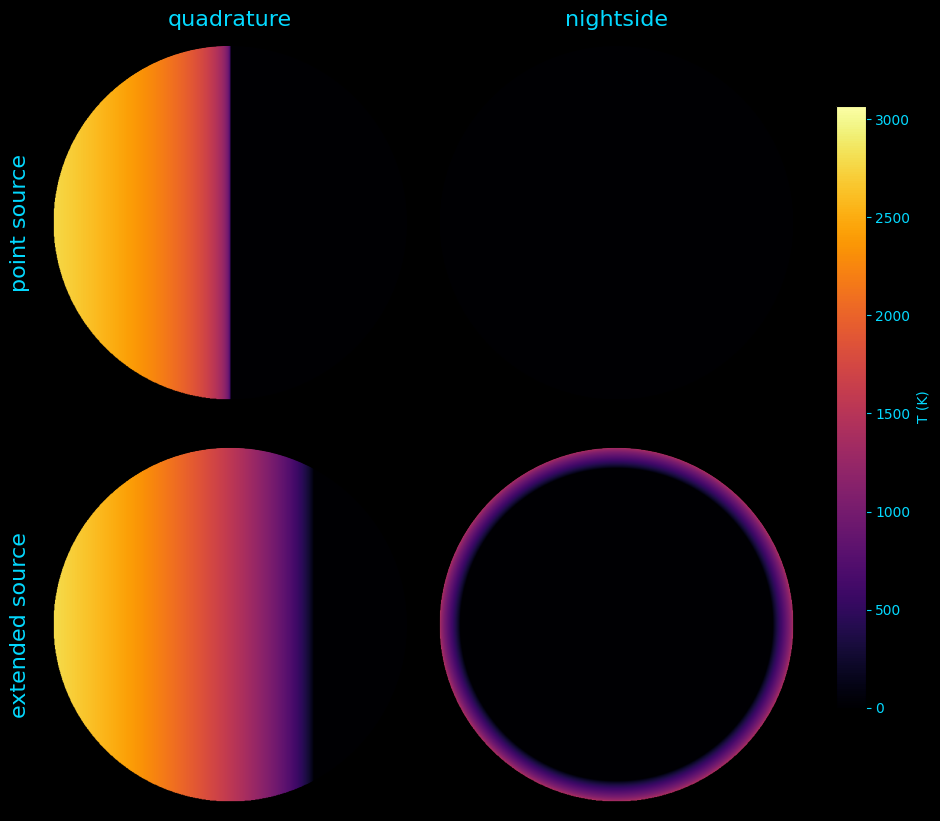

In [18]:
# 2 x 2: rows = insolation models, columns = viewing phases; one temperature scale (0 to 1.1 x the hotter substellar temperature) for all four panels
models = [("naive", "point source"), ("hyperillum", "extended source")]
phases = [(0.25, "quadrature"), (0.5, "nightside")]
A_B_map = 0.1                               # Bond albedo of the maps (the plot_*insolmap default); the maps above use the same value
theme = "black"                             # "white" for a light slide
bg, tc = ("black", "#04d9ff") if theme == "black" else ("white", "black")

T_hot = max(float(np.atleast_1d(surface_temperature(np.array([0.]), planet, m, u_B=u_B, A_B=A_B_map))[0]) for m, _ in models)
fig, axs = plt.subplots(len(models), len(phases), figsize=(2 * 4.3 / 0.865, 2 * 4.3), facecolor=bg)
for i, (model, model_label) in enumerate(models):
    for j, (phase, phase_label) in enumerate(phases):
        plot_insolmap(phase, planet, u_B=u_B, A_B=A_B_map, min_temp=0., max_temp=1.1 * T_hot, n_grid=600, ax=axs[i, j], theme=theme, show_cax=False,
                      terminator=False, show_penumbra=None, insolation_model=model, unit="temperature")
        if i == 0: axs[i, j].set_title(phase_label, color=tc, fontsize=16, pad=8)
    axs[i, 0].set_ylabel(model_label, color=tc, fontsize=16, labelpad=10)
    axs[i, 0].get_yaxis().set_visible(True); axs[i, 0].set_yticks([])   # the label only; plot_insolmap hides the axis
fig.subplots_adjust(wspace=0.02, hspace=0.08, left=0.07, right=0.84, top=0.93, bottom=0.03)
cbar = fig.colorbar(axs[0, 0].images[0], cax=fig.add_axes([0.87, 0.15, 0.03, 0.7]))
cbar.ax.tick_params(colors=tc); cbar.set_label("T (K)", color=tc)

plots_dir = f"Plots {planet.name.replace(' ', '')}"   # e.g. "Plots TOI-2431b", the folder the animations live in
os.makedirs(plots_dir, exist_ok=True)
fig.savefig(os.path.join(plots_dir, "tempmap_models_quadrature_nightside.png"), dpi=200, facecolor=bg)

In [19]:
from IPython.display import Image

# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="temperature", filename="tempmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="temperature", filename="tempmap_naive")
# animation_insolmap(planet, insolation_model="hyperillum", terminator=True, unit="flux", filename="fluxmap_hyperillum")
# animation_insolmap(planet, insolation_model="naive", terminator=False, unit="flux", filename="fluxmap_naive")

In [20]:
#Image(filename="tempmap_hyperillum.gif")

In [21]:
#Image(filename="tempmap_naive.gif")

In [22]:
#Image(filename="fluxmap_hyperillum.gif")

In [23]:
#Image(filename="fluxmap_naive.gif")